<a href="https://colab.research.google.com/github/yasiru20250101/telco-churn-classification/blob/main/notebooks/Task1_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1: Exploratory Data Analysis
**CM2604 Machine Learning: Coursework Part 01**

Explores the Telco Customer Churn dataset, visualises it and records the insights used in the report.

## Setup and data loading

In [43]:
# Import all libraries used in this notebook
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay,
                             accuracy_score, classification_report,
                             f1_score, precision_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
TARGET = "Churn"

# Folders for saving figures and results (downloaded at the end)
FIG_DIR = Path("figures")
RESULTS_DIR = Path("results")
FIG_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)


def save(fig, name):
    """Save a figure to figures/ and show it in the notebook."""
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()

In [44]:
GITHUB_USERNAME = "yasiru20250101"
REPO_NAME = "telco-churn-classification"
DATA_URL = (f"https://raw.githubusercontent.com/{GITHUB_USERNAME}/{REPO_NAME}"
            "/main/data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

raw = pd.read_csv(DATA_URL)
print("Shape:", raw.shape)
raw.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Data cleaning

In [45]:
print("Data types:")
print(raw.dtypes)
print("\nMissing values (NaN):", raw.isna().sum().sum())

# TotalCharges is stored as text: check for blank strings
blank_tc = raw["TotalCharges"].astype(str).str.strip() == ""
print("Blank strings in TotalCharges:", blank_tc.sum())
print("Tenure of those customers:", raw.loc[blank_tc, "tenure"].unique())

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Missing values (NaN): 0
Blank strings in TotalCharges: 11
Tenure of those customers: [0]


In [46]:
NUMERIC_FEATURES = ["tenure", "MonthlyCharges", "TotalCharges"]
CATEGORICAL_FEATURES = [
    "gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService",
    "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
    "Contract", "PaperlessBilling", "PaymentMethod",
]


def clean_data(df):
    """
    1. Drop customerID (unique identifier, no predictive value).
    2. Convert TotalCharges to numeric; blanks (tenure = 0) become NaN.
    3. Fill those NaN with 0 because new customers have not been charged yet.
    4. Convert SeniorCitizen 0/1 to No/Yes so it is treated as categorical.
    5. Encode the target: Yes -> 1, No -> 0.
    6. Remove duplicate rows.
    """
    df = df.copy()
    df = df.drop(columns=["customerID"])
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].astype(str).str.strip(),
                                       errors="coerce")
    df["TotalCharges"] = df["TotalCharges"].fillna(0)
    df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
    df[TARGET] = df[TARGET].map({"No": 0, "Yes": 1})
    before = len(df)
    df = df.drop_duplicates()
    print(f"Duplicate rows removed: {before - len(df)}")
    return df


df = clean_data(raw)
print("Clean shape:", df.shape)
df[NUMERIC_FEATURES].describe().round(2)

Duplicate rows removed: 22
Clean shape: (7021, 20)


,tenure,MonthlyCharges,TotalCharges
count,7021.00,7021.00,7021.00
mean,32.47,64.85,2286.77
std,24.53,30.07,2266.86
min,0.00,18.25,0.00
25%,9.00,35.75,403.35
50%,29.00,70.40,1400.55
75%,55.00,89.90,3801.70
max,72.00,118.75,8684.80


### 1 Class distribution

ChurnLabel
No     5164
Yes    1857
Name: count, dtype: int64
Churn rate: 26.45%


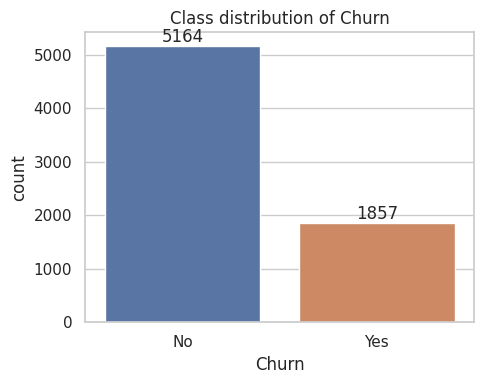

In [47]:
eda = df.copy()
eda["ChurnLabel"] = eda[TARGET].map({0: "No", 1: "Yes"})

print(eda["ChurnLabel"].value_counts())
print("Churn rate: %.2f%%" % (eda[TARGET].mean() * 100))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=eda, x="ChurnLabel", hue="ChurnLabel", legend=False, ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Class distribution of Churn")
ax.set_xlabel("Churn")
save(fig, "01_class_distribution.png")

### 2 Numeric features vs churn

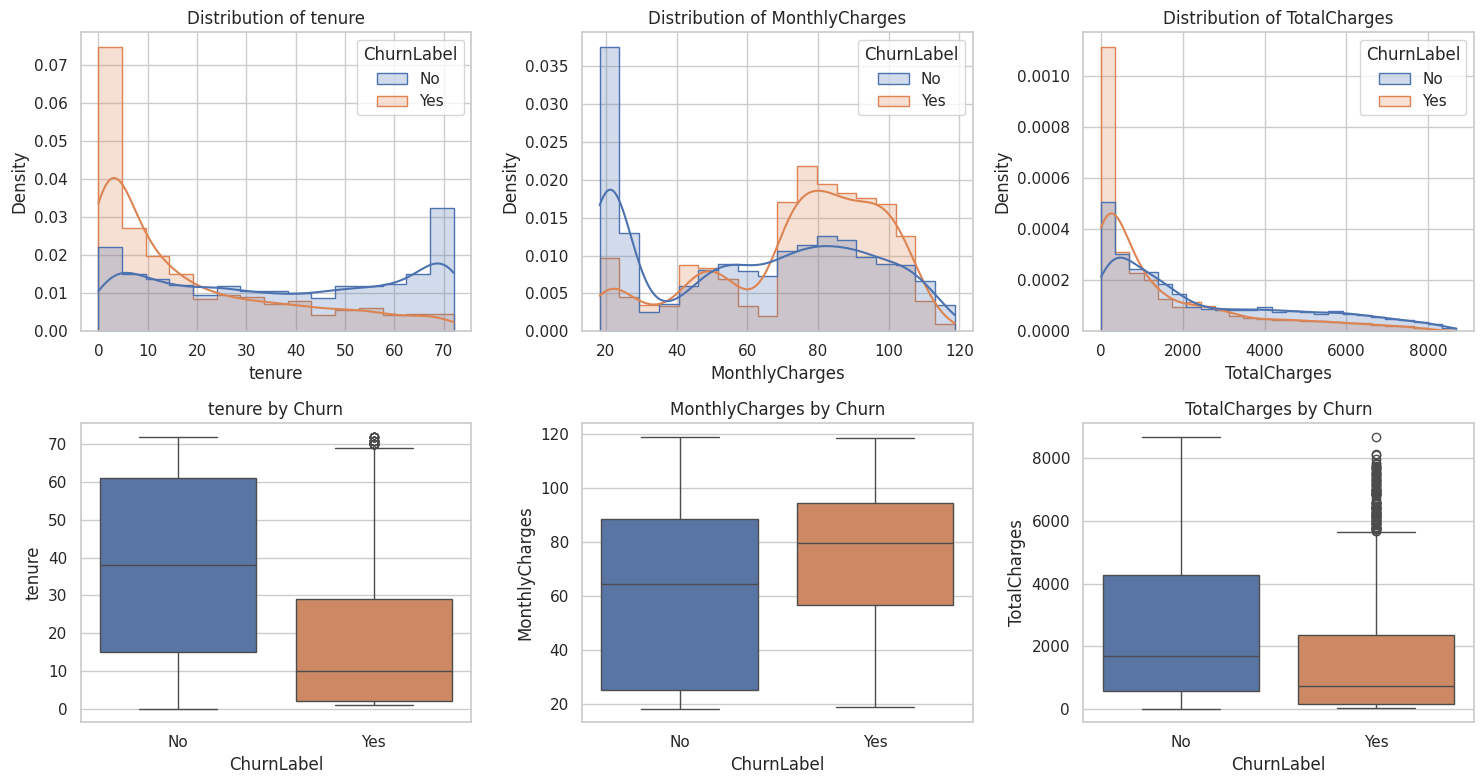

In [48]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(NUMERIC_FEATURES):
    sns.histplot(data=eda, x=col, hue="ChurnLabel", kde=True, element="step",
                 stat="density", common_norm=False, ax=axes[0, i])
    axes[0, i].set_title(f"Distribution of {col}")
    sns.boxplot(data=eda, x="ChurnLabel", y=col, hue="ChurnLabel",
                legend=False, ax=axes[1, i])
    axes[1, i].set_title(f"{col} by Churn")
save(fig, "02_numeric_vs_churn.png")

### 3 Churn rate by each categorical feature

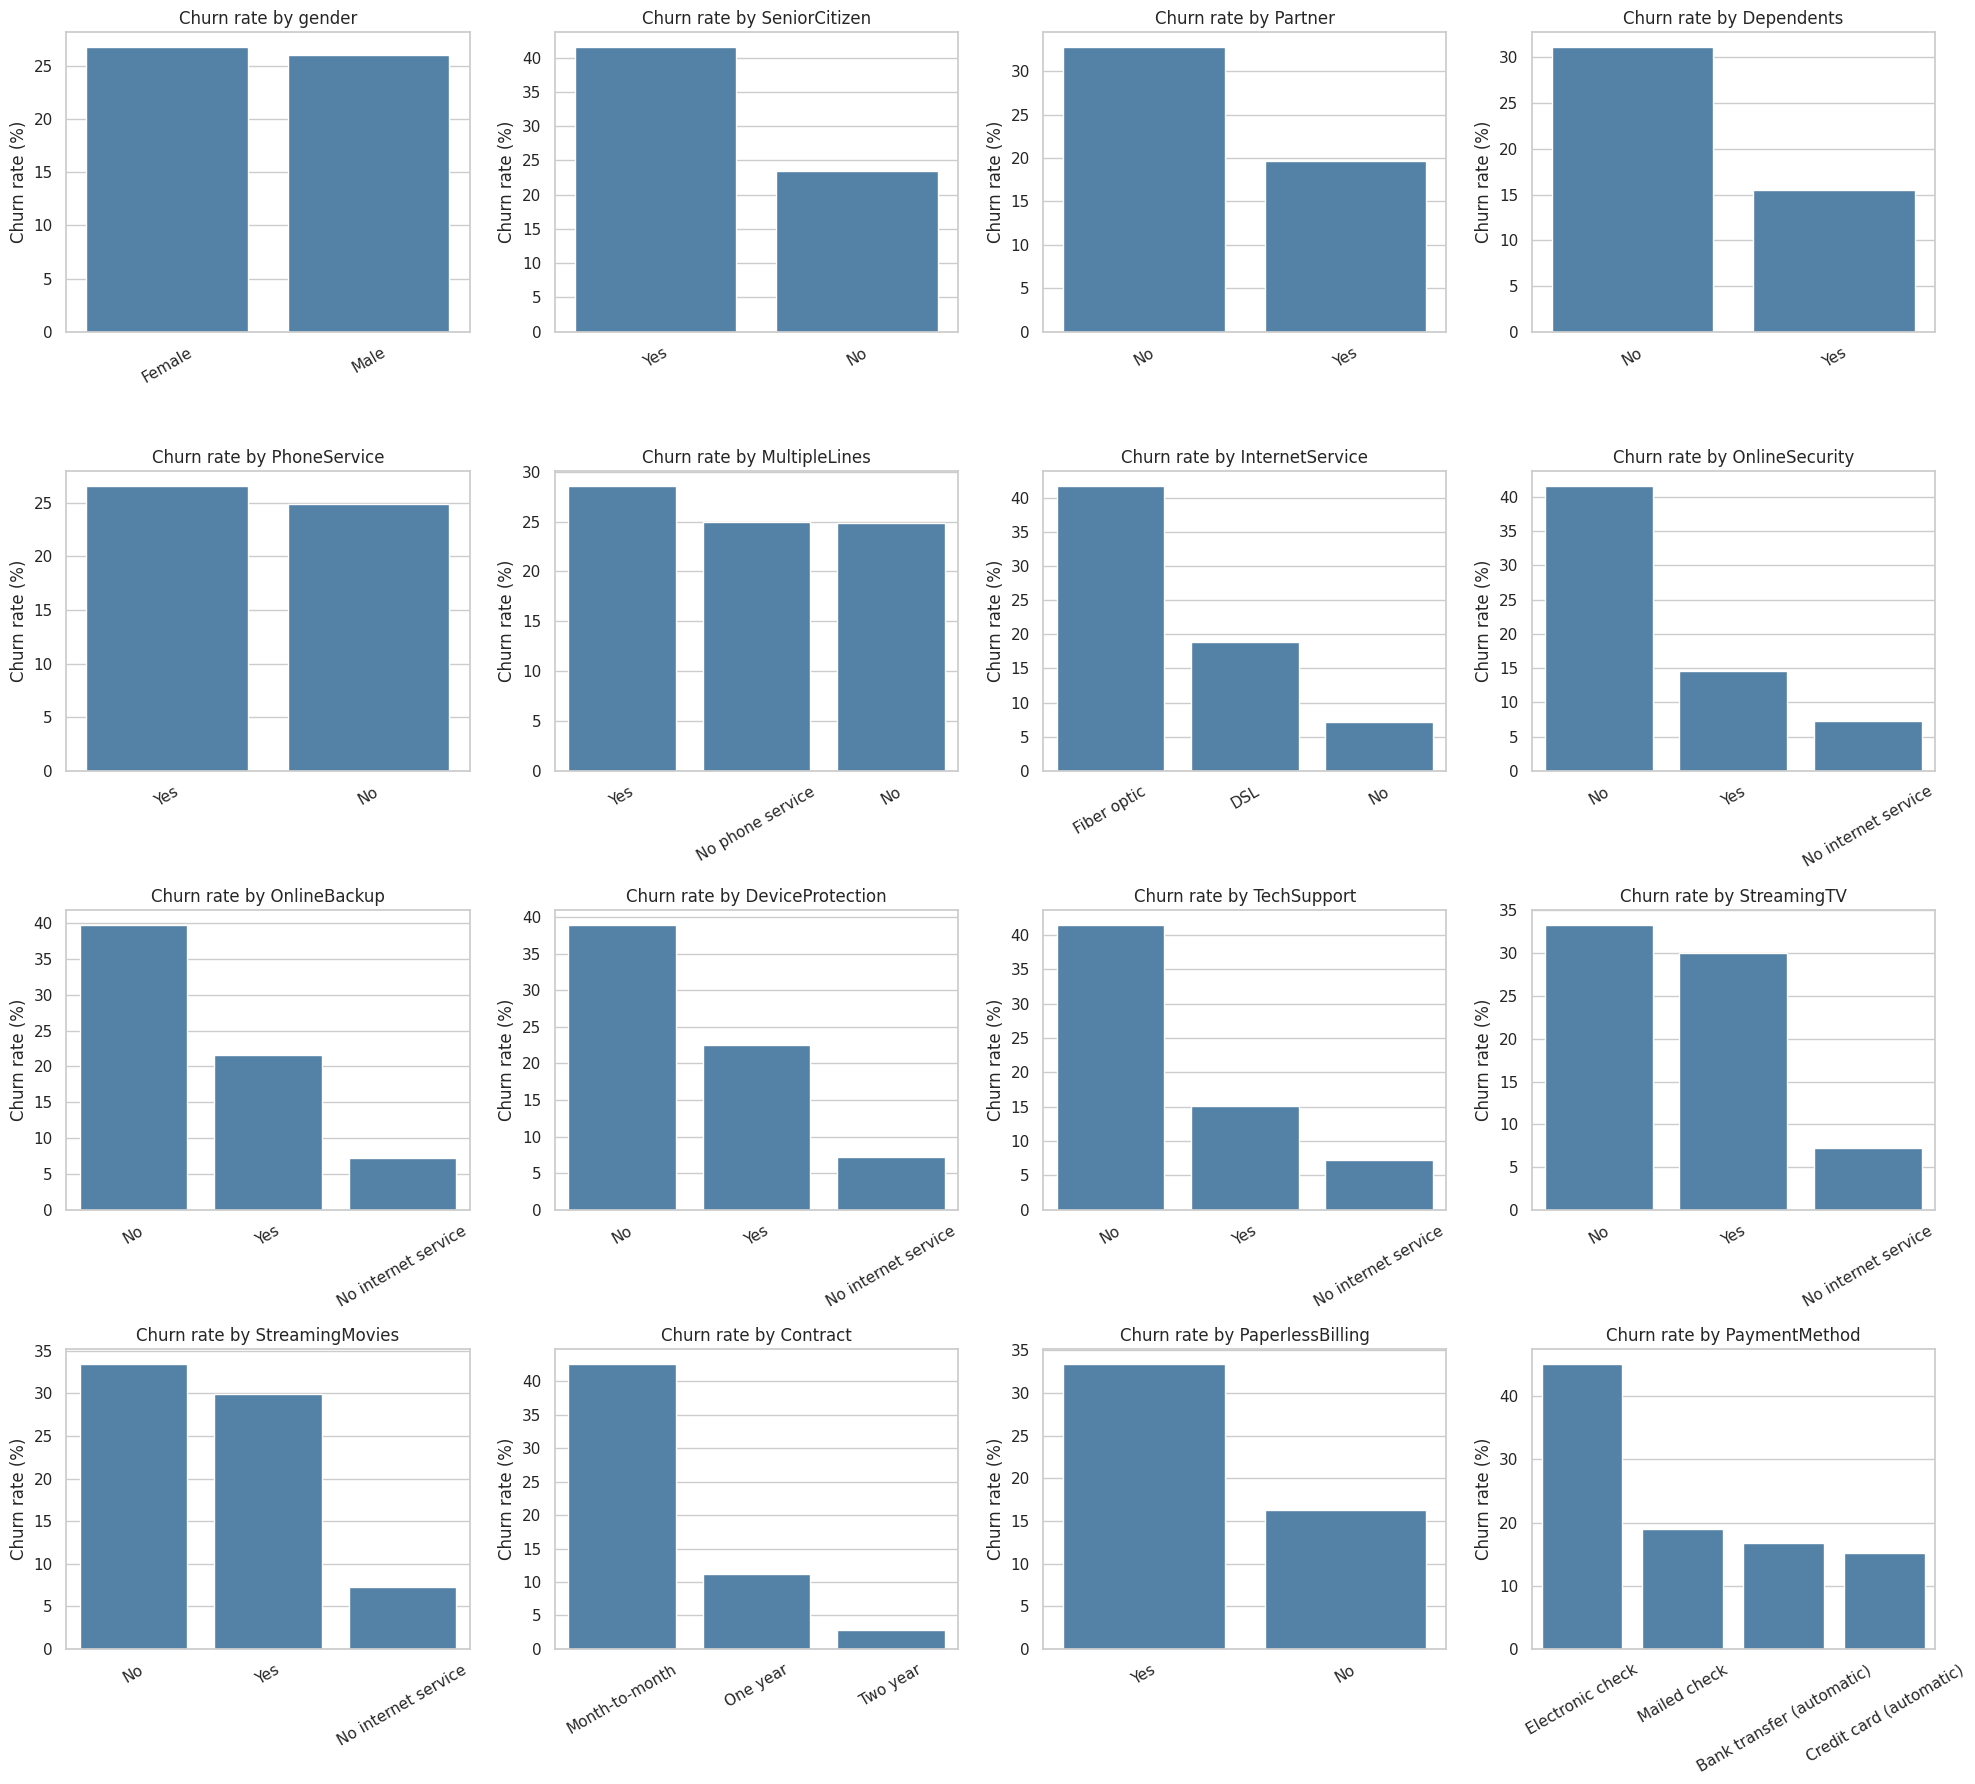


Churn rate (%) by Contract:
Contract
Month-to-month    42.6
One year          11.3
Two year           2.8

Churn rate (%) by InternetService:
InternetService
DSL            18.9
Fiber optic    41.8
No              7.2

Churn rate (%) by PaymentMethod:
PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Electronic check             45.1
Mailed check                 18.9

Churn rate (%) by TechSupport:
TechSupport
No                     41.5
No internet service     7.2
Yes                    15.2

Churn rate (%) by OnlineSecurity:
OnlineSecurity
No                     41.6
No internet service     7.2
Yes                    14.6

Churn rate (%) by SeniorCitizen:
SeniorCitizen
No     23.5
Yes    41.6

Churn rate (%) by gender:
gender
Female    26.8
Male      26.1


In [39]:
fig, axes = plt.subplots(4, 4, figsize=(20, 18))
for ax, col in zip(axes.flatten(), CATEGORICAL_FEATURES):
    rate = eda.groupby(col)[TARGET].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.index, y=rate.values, ax=ax, color="steelblue")
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate (%)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
save(fig, "03_churn_rate_by_category.png")

# Churn rates to quote in the report
for col in ["Contract", "InternetService", "PaymentMethod", "TechSupport",
            "OnlineSecurity", "SeniorCitizen", "gender"]:
    print(f"\nChurn rate (%) by {col}:")
    print((eda.groupby(col)[TARGET].mean() * 100).round(1).to_string())

### 4 Contract type and tenure

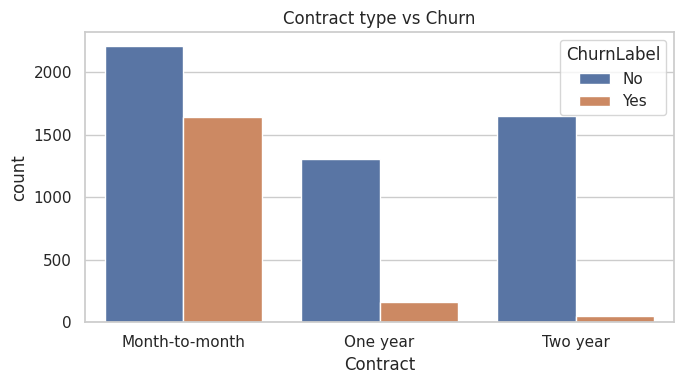

Churn rate (%) by tenure group:
TenureGroup
0-12     47.4
13-24    28.7
25-48    20.4
49-72     9.5


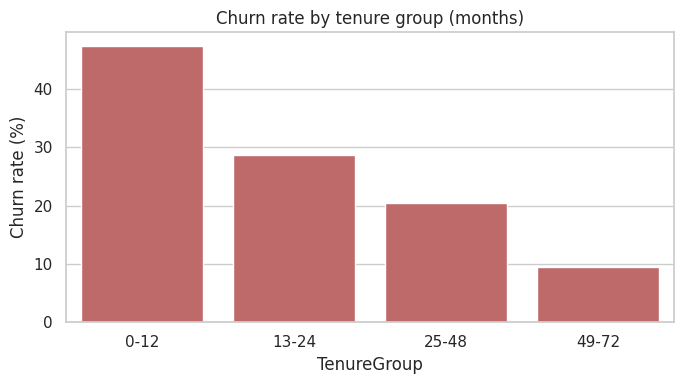

In [40]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=eda, x="Contract", hue="ChurnLabel", ax=ax)
ax.set_title("Contract type vs Churn")
save(fig, "04_contract_vs_churn.png")

eda["TenureGroup"] = pd.cut(eda["tenure"], bins=[-1, 12, 24, 48, 72],
                            labels=["0-12", "13-24", "25-48", "49-72"])
rate = eda.groupby("TenureGroup", observed=True)[TARGET].mean() * 100
print("Churn rate (%) by tenure group:")
print(rate.round(1).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=rate.index, y=rate.values, ax=ax, color="indianred")
ax.set_title("Churn rate by tenure group (months)")
ax.set_ylabel("Churn rate (%)")
save(fig, "05_tenure_group_churn.png")

### 5 Correlation and tenure vs monthly charges

                tenure  MonthlyCharges  TotalCharges  Churn
tenure            1.00            0.25          0.83  -0.35
MonthlyCharges    0.25            1.00          0.65   0.19
TotalCharges      0.83            0.65          1.00  -0.20
Churn            -0.35            0.19         -0.20   1.00


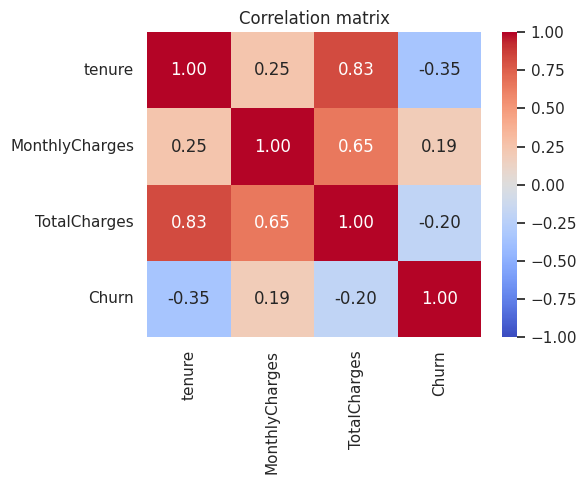

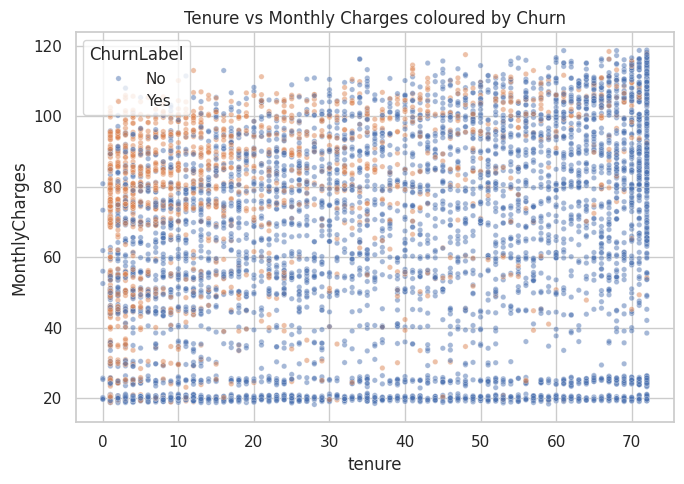

In [41]:
corr = eda[NUMERIC_FEATURES + [TARGET]].corr()
print(corr.round(2))

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation matrix")
save(fig, "06_correlation_heatmap.png")

fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=eda, x="tenure", y="MonthlyCharges", hue="ChurnLabel",
                alpha=0.5, s=15, ax=ax)
ax.set_title("Tenure vs Monthly Charges coloured by Churn")
save(fig, "07_tenure_vs_monthly.png")

### EDA insights

1. **Class imbalance:** only [26.5]% of customers churned ([1869] Yes vs [5174] No), so accuracy alone is misleading and F1/recall will be used.
2. **Data quality:** TotalCharges had [11] blank values, all for customers with tenure 0, so they were filled with 0.
3. **Contract:** month-to-month customers churn the most ([42.7]%) compared to two-year contracts ([2.8]%).
4. **Tenure:** customers in their first 12 months churn the most ([47.4]%); long-tenure customers rarely leave.
5. **Internet service:** fiber optic customers have the highest churn ([41.9]%).
6. **Payment method:** electronic check users churn the most ([45.3]%).
7. **Add-on services:** customers without TechSupport ([41.6]%) or OnlineSecurity churn more.
8. **Senior citizens** churn more ([41.7]% vs [23.6]%), while **gender** has almost no effect.
9. **Correlation:** TotalCharges is strongly correlated with tenure ([0.83]).


## Download figures and results

In [42]:
# Zip the figures/ and results/ folders and download them for the report
import shutil
shutil.make_archive("task1_figures", "zip", ".", "figures")
shutil.make_archive("task1_results", "zip", ".", "results")

try:
    from google.colab import files
    files.download("task1_figures.zip")
    files.download("task1_results.zip")
except ImportError:
    print("Not running in Colab: zip files saved in the current folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>